> ⚠️ **SUPERSEDED — kept for the audit trail only.**
>
> This notebook's "test" set is a `validation_split=0.1` subset of the same folder, so it lies *inside* the validation split used for checkpoint selection; its 98.4 % is not a held-out result, and the "10,032 images" count is a Windows `*.jpg` + `*.JPG` double count of 5,016 files.
>
> The reproducible Module 3 pipeline is `scripts/m3_train_classifier.py` (de-duplicated, seeded, stratified 70/15/15 split with a manifest). Results: `notebooks/m3_classification_701515_report.ipynb` and `docs/MODULE3_REPORT.md`.

# SmartSpray — M3: Disease Classification Training Trials

**Purpose:** Train an EfficientNetB0 classifier to identify tomato diseases.

**Diseases targeted:**
- `early_blight`
- `late_blight`
- `septoria_leaf_spot`
- `healthy`

**Dataset:** PlantVillage (subset: tomato classes only)

**This notebook is for experimentation only.**  
Production code lives in `app/classification/classifier.py`.

**Run every cell in order. Do not skip.**


In [2]:
import sys
import os
import shutil
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import cv2

# Suppress TensorFlow info/warning logs (set to '3' to hide all, '0' to show all)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Input
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print(f'Python   : {sys.version}')
print(f'TensorFlow: {tf.__version__}')
print(f'GPU available: {bool(tf.config.list_physical_devices("GPU"))}')
print('\nAll imports successful.')

Python   : 3.12.4 (tags/v3.12.4:8e8a4ba, Jun  6 2024, 19:30:16) [MSC v.1940 64 bit (AMD64)]
TensorFlow: 2.21.0
GPU available: False

All imports successful.


## CELL 2 — Configuration

**ACTION REQUIRED:**  
Set `DATASET_ROOT` to the folder containing the PlantVillage tomato class subfolders.  

Expected structure:
```
DATASET_ROOT/
├── Tomato___Early_blight/    ← folder name may vary slightly
├── Tomato___Late_blight/
├── Tomato___Septoria_leaf_spot/
└── Tomato___healthy/
```

Download PlantVillage from: https://www.kaggle.com/datasets/emmarex/plantdisease  
After downloading, extract and point `DATASET_ROOT` at the folder containing the 4 tomato subfolders.

In [3]:
# ── USER MUST EDIT THIS LINE ─────────────────────────────────────────────────
DATASET_ROOT = Path("../data/datasets/plantvillage_tomato")  # Change this path
# ─────────────────────────────────────────────────────────────────────────────

REPO_ROOT    = Path("../").resolve()
MODEL_DIR    = REPO_ROOT / "models" / "classification"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# These are the SmartSpray canonical disease label names.
# They must match the CLASS_NAMES list in app/classification/classifier.py exactly.
CLASS_NAMES  = ["early_blight", "late_blight", "septoria_leaf_spot", "healthy"]
NUM_CLASSES  = len(CLASS_NAMES)

# Maps PlantVillage folder names → canonical SmartSpray labels.
# Adjust the keys if your downloaded folder names differ slightly.
FOLDER_TO_LABEL = {
    "Tomato___Early_blight":       "early_blight",
    "Tomato___Late_blight":        "late_blight",
    "Tomato___Septoria_leaf_spot": "septoria_leaf_spot",
    "Tomato___healthy":            "healthy",
    # Common alternate spellings:
    "Tomato_Early_blight":         "early_blight",
    "Tomato_Late_blight":          "late_blight",
    "Tomato_Septoria_leaf_spot":   "septoria_leaf_spot",
    "Tomato_healthy":              "healthy",
}

# Model hyperparameters
IMAGE_SIZE     = 224     # EfficientNetB0 native input size
BATCH_SIZE     = 32
EPOCHS_HEAD    = 20      # Phase 1: train only the head (backbone frozen)
EPOCHS_FINETUNE = 10     # Phase 2: fine-tune top backbone layers
LR_HEAD        = 1e-3
LR_FINETUNE    = 1e-5
DROPOUT_RATE   = 0.3

RANDOM_SEED    = 42
tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print(f'Dataset root : {DATASET_ROOT}')
print(f'Model output : {MODEL_DIR}')
print(f'Classes      : {CLASS_NAMES}')

Dataset root : ..\data\datasets\plantvillage_tomato
Model output : D:\RIDDHIMA SINGH\SmartSpray\models\classification
Classes      : ['early_blight', 'late_blight', 'septoria_leaf_spot', 'healthy']


## CELL 3 — Dataset Verification

Checks that the expected class folders exist and counts images per class.
Fix any issues before proceeding to training.

In [4]:
assert DATASET_ROOT.exists(), (
    f"Dataset root not found: {DATASET_ROOT}\n"
    "Download PlantVillage and update DATASET_ROOT in Cell 2."
)

# Find folders that map to our target classes
found_folders = {}
for folder in DATASET_ROOT.iterdir():
    if folder.is_dir() and folder.name in FOLDER_TO_LABEL:
        label = FOLDER_TO_LABEL[folder.name]
        found_folders[label] = folder

missing = [c for c in CLASS_NAMES if c not in found_folders]
assert not missing, (
    f"Missing class folders for: {missing}\n"
    f"Found folders: {[f.name for f in DATASET_ROOT.iterdir() if f.is_dir()]}\n"
    "Update FOLDER_TO_LABEL mapping in Cell 2 to match your folder names."
)

print("Class distribution:")
total = 0
for label in CLASS_NAMES:
    folder = found_folders[label]
    images = list(folder.glob("*.jpg")) + list(folder.glob("*.JPG")) + list(folder.glob("*.png"))
    print(f"  {label:30s}: {len(images):>5} images  ←  {folder.name}")
    total += len(images)

print(f"\n  {'TOTAL':30s}: {total:>5} images")
print("\n✅ Dataset verification passed.")

Class distribution:
  early_blight                  :  1600 images  ←  Tomato___Early_blight
  late_blight                   :  3052 images  ←  Tomato___Late_blight
  septoria_leaf_spot            :  2834 images  ←  Tomato___Septoria_leaf_spot
  healthy                       :  2546 images  ←  Tomato___healthy

  TOTAL                         : 10032 images

✅ Dataset verification passed.


## CELL 4 — Visualize Classes

Always look at your training data before training.  
If any image looks corrupted or mislabeled, investigate before proceeding.

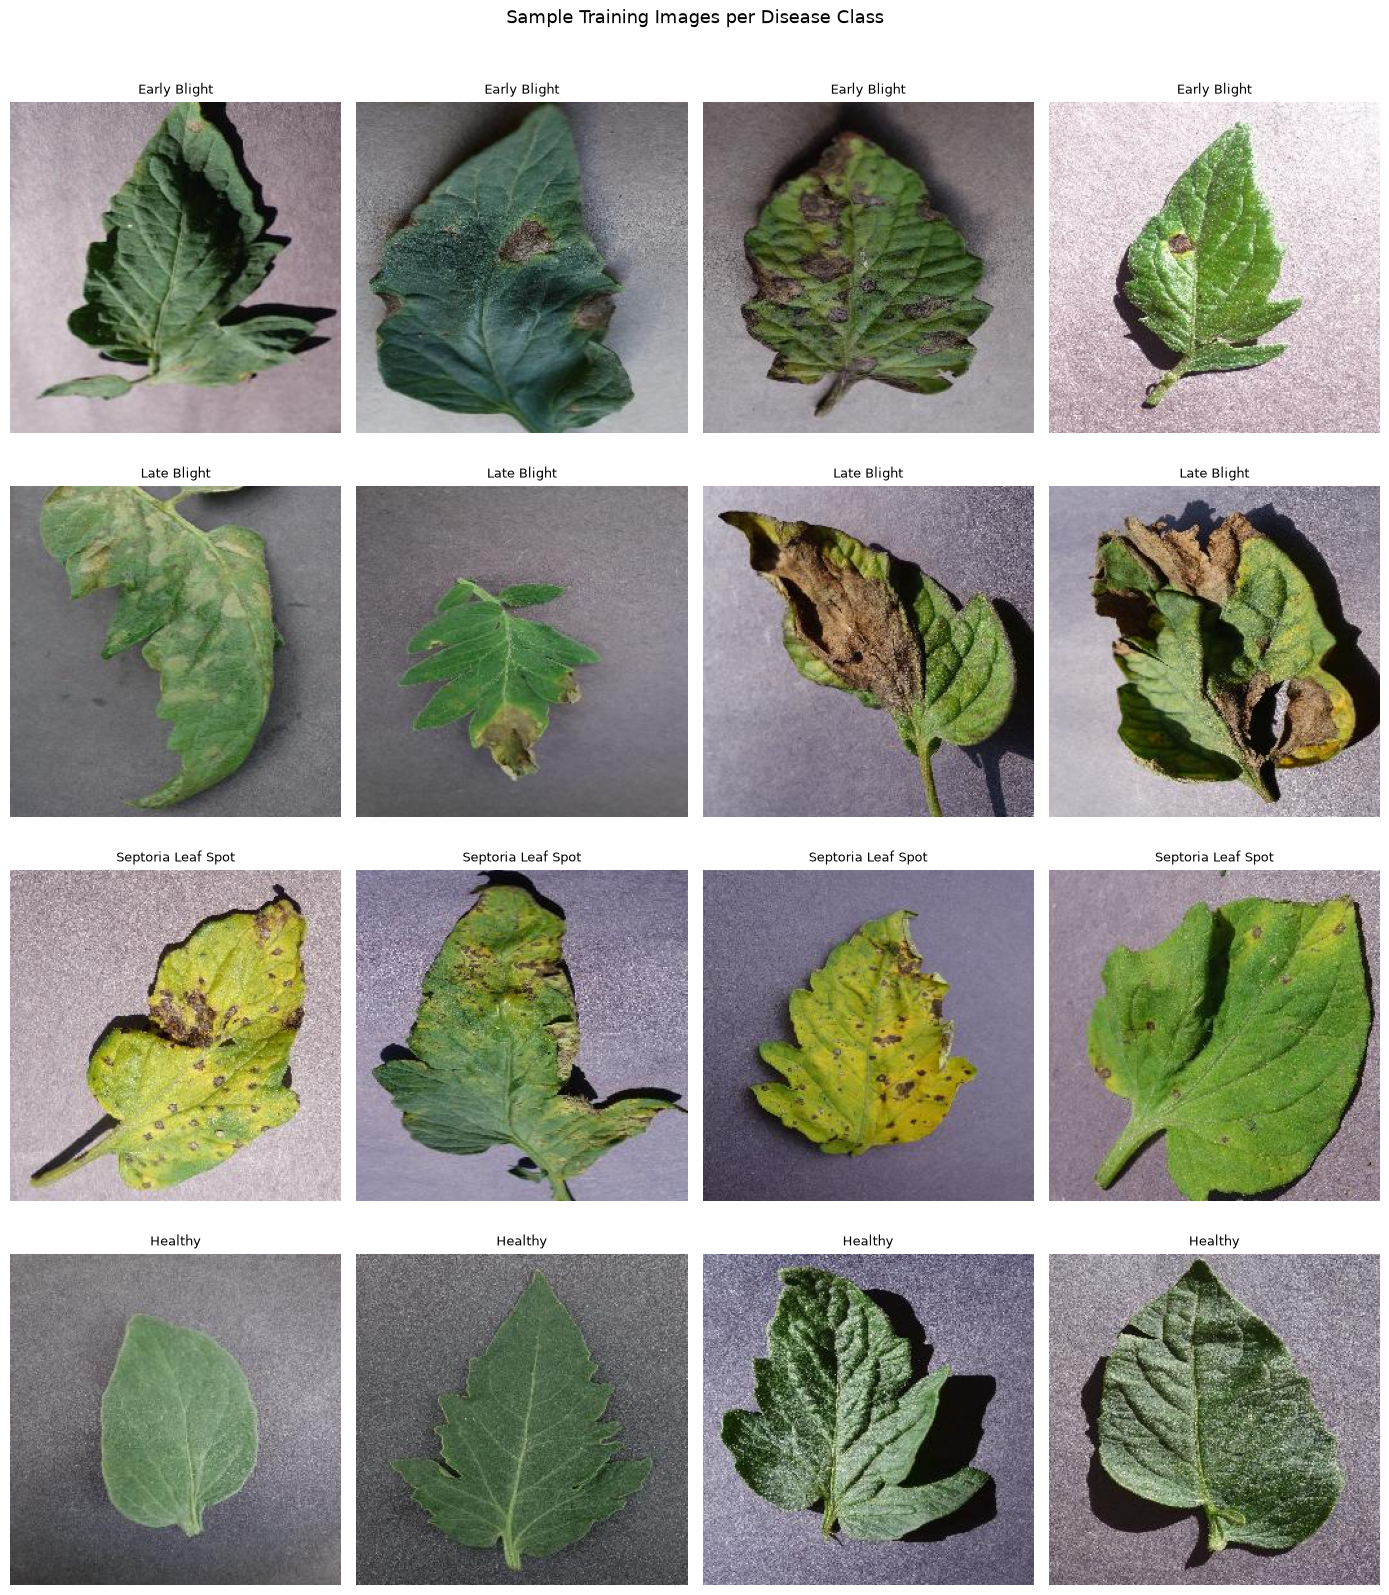

Verify: each row should show a distinct disease appearance.


In [5]:
fig, axes = plt.subplots(NUM_CLASSES, 4, figsize=(14, 4 * NUM_CLASSES))

for row_idx, label in enumerate(CLASS_NAMES):
    folder = found_folders[label]
    all_images = list(folder.glob("*.jpg")) + list(folder.glob("*.JPG")) + list(folder.glob("*.png"))
    samples = random.sample(all_images, min(4, len(all_images)))

    for col_idx, img_path in enumerate(samples):
        ax = axes[row_idx][col_idx] if NUM_CLASSES > 1 else axes[col_idx]
        img = cv2.imread(str(img_path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        ax.imshow(img)
        ax.set_title(label.replace("_", " ").title(), fontsize=9)
        ax.axis("off")

plt.suptitle("Sample Training Images per Disease Class", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()
print("Verify: each row should show a distinct disease appearance.")

## CELL 5 — Data Augmentation and Generator Setup

**Why augment?**  
The model will be applied to crops cut from drone images — different lighting, angles, scales.  
Augmentation during training forces the model to generalise beyond exact pixel positions.

**Why NOT augment the validation set?**  
Validation must measure performance on *realistic* inputs. Augmenting it would give a misleading accuracy number.

In [6]:
# ── Build a prepared dataset directory (reorganise into class subfolders) ─────
# ImageDataGenerator's flow_from_directory expects:
#   prepared_dir/
#     early_blight/
#     late_blight/
#     ...

PREPARED_DIR = MODEL_DIR / "prepared_dataset"

if not PREPARED_DIR.exists():
    print("Preparing dataset (copying images to canonical folder names)...")
    for label in CLASS_NAMES:
        src = found_folders[label]
        dst = PREPARED_DIR / label
        dst.mkdir(parents=True, exist_ok=True)
        for img in src.glob("*.jpg"):
            shutil.copy2(img, dst)
        for img in src.glob("*.JPG"):
            shutil.copy2(img, dst)
        for img in src.glob("*.png"):
            shutil.copy2(img, dst)
    print(f"Prepared dataset at: {PREPARED_DIR}")
else:
    print(f"Using existing prepared dataset: {PREPARED_DIR}")

# ── Training augmentation ─────────────────────────────────────────────────────
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,   # EfficientNetB0 scaling
    validation_split=0.2,                       # 80% train, 20% validation
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    horizontal_flip=True,
    vertical_flip=False,                        # leaf images rarely appear upside-down
    zoom_range=0.15,
    brightness_range=[0.8, 1.2],
    fill_mode="nearest"
)

# Validation: only preprocessing, no augmentation
val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    PREPARED_DIR,
    target_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    seed=RANDOM_SEED,
    shuffle=True
)

val_generator = val_datagen.flow_from_directory(
    PREPARED_DIR,
    target_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    seed=RANDOM_SEED,
    shuffle=False
)

# IMPORTANT: verify the class index mapping matches CLASS_NAMES
# Keras assigns indices alphabetically by default.
print("\nKeras class index mapping:")
for cls_name, idx in sorted(train_generator.class_indices.items(), key=lambda x: x[1]):
    print(f"  Index {idx} → {cls_name}")

# Store the ordered class list (alphabetical, as Keras assigns it)
KERAS_CLASS_ORDER = [None] * NUM_CLASSES
for cls_name, idx in train_generator.class_indices.items():
    KERAS_CLASS_ORDER[idx] = cls_name

print(f"\nKERAS_CLASS_ORDER (must be saved alongside the model): {KERAS_CLASS_ORDER}")
print(f"\nTraining samples  : {train_generator.samples}")
print(f"Validation samples: {val_generator.samples}")

Using existing prepared dataset: D:\RIDDHIMA SINGH\SmartSpray\models\classification\prepared_dataset
Found 4014 images belonging to 4 classes.
Found 1002 images belonging to 4 classes.

Keras class index mapping:
  Index 0 → early_blight
  Index 1 → healthy
  Index 2 → late_blight
  Index 3 → septoria_leaf_spot

KERAS_CLASS_ORDER (must be saved alongside the model): ['early_blight', 'healthy', 'late_blight', 'septoria_leaf_spot']

Training samples  : 4014
Validation samples: 1002


## CELL 6 — Model Definition

**Architecture:**
```
EfficientNetB0 (ImageNet pretrained, frozen)
    ↓
GlobalAveragePooling2D
    ↓
Dropout(0.3)
    ↓
Dense(256, ReLU)
    ↓
Dropout(0.2)
    ↓
Dense(4, Softmax)  ← one output per class
```

In [7]:
def build_model(num_classes: int, image_size: int = 224, dropout: float = 0.3) -> tf.keras.Model:
    """
    Build an EfficientNetB0 transfer-learning model for plant disease classification.

    Phase 1 (training the head only):
        The EfficientNetB0 backbone weights are frozen — they were trained on
        ImageNet and already contain powerful low-level feature detectors.
        Only the new Dense layers are trained.

    Phase 2 (fine-tuning, Cell 7):
        The top ~30 backbone layers are unfrozen with a very low learning rate
        to adapt the features toward plant disease patterns.
    """
    base_model = EfficientNetB0(
        weights="imagenet",
        include_top=False,             # remove ImageNet's final Dense layer
        input_shape=(image_size, image_size, 3)
    )
    base_model.trainable = False       # freeze backbone for Phase 1

    inputs = Input(shape=(image_size, image_size, 3))
    x = base_model(inputs, training=False)   # training=False keeps BN layers frozen
    x = GlobalAveragePooling2D()(x)
    x = Dropout(dropout)(x)
    x = Dense(256, activation="relu")(x)
    x = Dropout(dropout * 0.67)(x)     # 0.2 when dropout=0.3
    outputs = Dense(num_classes, activation="softmax")(x)

    model = Model(inputs=inputs, outputs=outputs)
    return model, base_model


model, base_model = build_model(NUM_CLASSES, IMAGE_SIZE, DROPOUT_RATE)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_HEAD),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model summary (head only, backbone frozen):")
print(f"  Total parameters    : {model.count_params():>12,}")
print(f"  Trainable parameters: {sum(tf.size(v).numpy() for v in model.trainable_variables):>12,}")
print(f"  Frozen parameters   : {sum(tf.size(v).numpy() for v in model.non_trainable_variables):>12,}")

Model summary (head only, backbone frozen):
  Total parameters    :    4,378,535
  Trainable parameters:      328,964
  Frozen parameters   :    4,049,593


## CELL 7 — Training

**Phase 1:** Train only the new Dense head. Backbone is frozen.
**Phase 2:** Unfreeze the top 30 backbone layers and fine-tune with a much smaller learning rate.

In [7]:
checkpoint_path = str(MODEL_DIR / "checkpoint_best.keras")

callbacks = [
    ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

# ── Phase 1: Train head only ──────────────────────────────────────────────────
print("═" * 60)
print("Phase 1 — Training head (backbone frozen)")
print("═" * 60)

history_phase1 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS_HEAD,
    callbacks=callbacks,
    verbose=1
)

print(f"\nPhase 1 complete. Best val_accuracy: {max(history_phase1.history['val_accuracy']):.4f}")

# ── Phase 2: Fine-tune top backbone layers ────────────────────────────────────
print("\n" + "═" * 60)
print("Phase 2 — Fine-tuning top 30 backbone layers")
print("═" * 60)

# Unfreeze only the last 30 layers of the backbone
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Recompile with a much smaller learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_FINETUNE),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_phase2 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS_FINETUNE,
    callbacks=callbacks,
    verbose=1
)

print(f"\nPhase 2 complete. Best val_accuracy: {max(history_phase2.history['val_accuracy']):.4f}")

════════════════════════════════════════════════════════════
Phase 1 — Training head (backbone frozen)
════════════════════════════════════════════════════════════
Epoch 1/20
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8124 - loss: 0.4667
Epoch 1: val_accuracy improved from None to 0.93014, saving model to D:\RIDDHIMA SINGH\SmartSpray\models\classification\checkpoint_best.keras

Epoch 1: finished saving model to D:\RIDDHIMA SINGH\SmartSpray\models\classification\checkpoint_best.keras
126/126 ━━━━━━━━━━━━━━━━━━━━ 247s 2s/step - accuracy: 0.8124 - loss: 0.4667 - val_accuracy: 0.9301 - val_loss: 0.2239 - learning_rate: 0.0010
Epoch 2/20
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 984ms/step - accuracy: 0.8994 - loss: 0.2682
Epoch 2: val_accuracy improved from 0.93014 to 0.93912, saving model to D:\RIDDHIMA SINGH\SmartSpray\models\classification\checkpoint_best.keras

Epoch 2: finished saving model to D:\RIDDHIMA SINGH\SmartSpray\models\classification\checkpoint_best.keras
126/126 ━━━━━━━━━━

## CELL 8 — Validation Curves

Plot training and validation accuracy/loss across both phases.
Look for: accuracy increasing, loss decreasing, no major gap between train and val (overfitting).

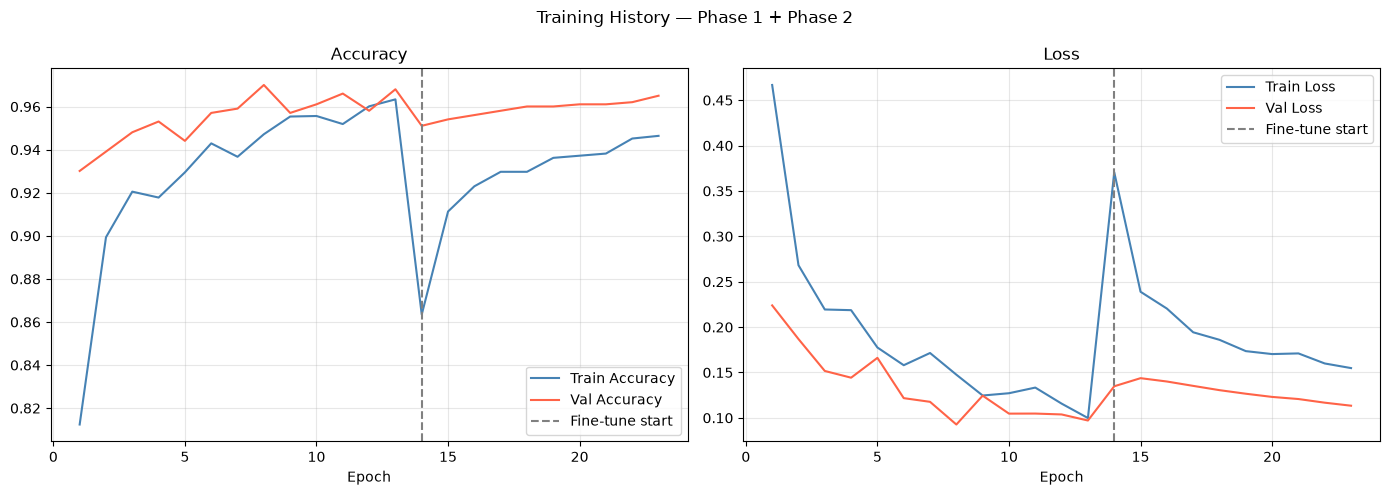

In [8]:
# Combine both training phases
all_val_acc  = history_phase1.history["val_accuracy"]  + history_phase2.history["val_accuracy"]
all_train_acc = history_phase1.history["accuracy"]     + history_phase2.history["accuracy"]
all_val_loss  = history_phase1.history["val_loss"]     + history_phase2.history["val_loss"]
all_train_loss = history_phase1.history["loss"]        + history_phase2.history["loss"]

epochs_range = range(1, len(all_val_acc) + 1)
phase2_start = len(history_phase1.history["val_accuracy"]) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(epochs_range, all_train_acc, label="Train Accuracy", color="steelblue")
axes[0].plot(epochs_range, all_val_acc,   label="Val Accuracy",   color="tomato")
axes[0].axvline(phase2_start, color="gray", linestyle="--", label="Fine-tune start")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss
axes[1].plot(epochs_range, all_train_loss, label="Train Loss", color="steelblue")
axes[1].plot(epochs_range, all_val_loss,   label="Val Loss",   color="tomato")
axes[1].axvline(phase2_start, color="gray", linestyle="--", label="Fine-tune start")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle("Training History — Phase 1 + Phase 2", fontsize=12)
plt.tight_layout()
plt.show()

## CELL 9 — Test Evaluation

Evaluate on a held-out test set that was never seen during training or validation.  
This is the number you report in your project write-up.

In [11]:

checkpoint_path = str(MODEL_DIR / "checkpoint_best.keras")

print(checkpoint_path)

D:\RIDDHIMA SINGH\SmartSpray\models\classification\checkpoint_best.keras


In [12]:
# Build a test generator from the same prepared directory.
# Use a DIFFERENT split: 10% for test (held out from both train and val).
# For PlantVillage's large class counts this gives hundreds of test samples per class.
test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.1
)

test_generator = test_datagen.flow_from_directory(
    PREPARED_DIR,
    target_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",  # the 10% split we reserved
    shuffle=False          # must be False for confusion matrix to be correct
)

# Load the best checkpoint (may differ from current weights if early stopping fired)
best_model = tf.keras.models.load_model(checkpoint_path)

test_loss, test_acc = best_model.evaluate(test_generator, verbose=0)
print(f"TEST LOSS    : {test_loss:.4f}")
print(f"TEST ACCURACY: {test_acc:.4f}  ({test_acc*100:.1f}%)")

if test_acc < 0.80:
    print("\n⚠️  Accuracy below 80%. Consider: more epochs, more fine-tuning layers, or adding your own field crops.")
else:
    print("\n✅ Test accuracy acceptable. Proceed to Cell 10.")

Found 500 images belonging to 4 classes.
TEST LOSS    : 0.0679
TEST ACCURACY: 0.9840  (98.4%)

✅ Test accuracy acceptable. Proceed to Cell 10.


## CELL 10 — Confusion Matrix

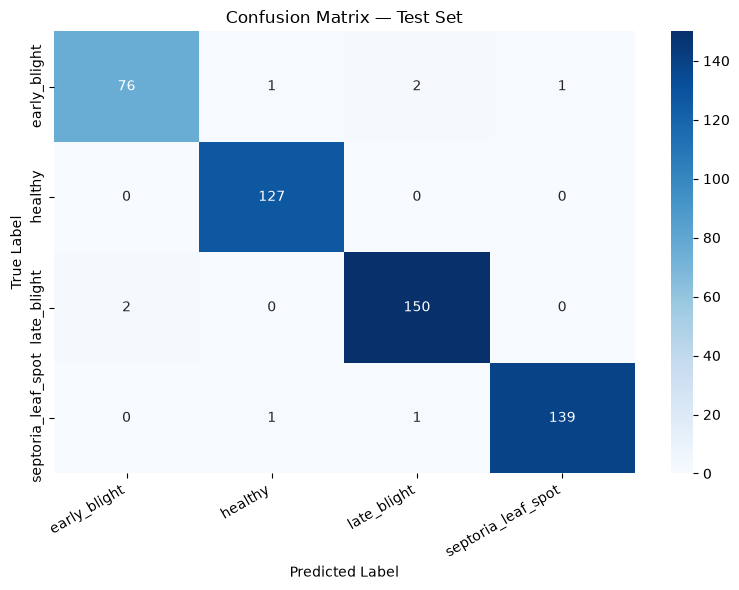

Diagonal = correct predictions.
Off-diagonal = misclassifications (the module that most benefits from more data).


In [13]:
# Generate predictions on the full test set
y_pred_probs = best_model.predict(test_generator, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_generator.classes

cm = confusion_matrix(y_true, y_pred)

# KERAS_CLASS_ORDER was defined in Cell 5 (alphabetical, as Keras assigns)
ordered_labels = KERAS_CLASS_ORDER

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True, fmt="d",
    xticklabels=ordered_labels,
    yticklabels=ordered_labels,
    cmap="Blues"
)
plt.title("Confusion Matrix — Test Set")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

print("Diagonal = correct predictions.")
print("Off-diagonal = misclassifications (the module that most benefits from more data).")

## CELL 11 — Classification Report

In [14]:
report = classification_report(
    y_true,
    y_pred,
    target_names=ordered_labels,
    digits=4
)
print("Classification Report:")
print(report)

print("\nPer-class breakdown:")
print("  - Recall tells you: of all actual [disease] leaves, how many did we catch?")
print("  - Precision tells you: of all leaves we predicted as [disease], how many were actually that disease?")
print("  - Low Recall on a disease = some infected plants will be missed → treated as healthy (dangerous)")
print("  - Low Precision = some healthy leaves classified as diseased → wasted pesticide (bad but safer)")

Classification Report:
                    precision    recall  f1-score   support

      early_blight     0.9744    0.9500    0.9620        80
           healthy     0.9845    1.0000    0.9922       127
       late_blight     0.9804    0.9868    0.9836       152
septoria_leaf_spot     0.9929    0.9858    0.9893       141

          accuracy                         0.9840       500
         macro avg     0.9830    0.9807    0.9818       500
      weighted avg     0.9840    0.9840    0.9839       500


Per-class breakdown:
  - Recall tells you: of all actual [disease] leaves, how many did we catch?
  - Precision tells you: of all leaves we predicted as [disease], how many were actually that disease?
  - Low Recall on a disease = some infected plants will be missed → treated as healthy (dangerous)
  - Low Precision = some healthy leaves classified as diseased → wasted pesticide (bad but safer)


## CELL 12 — Save Best Model

Save the final model weights in Keras format.
This is a staging save — Cell 13 copies it to the production location.

In [15]:
# Save the class order alongside the model so the production code can validate it.
import json

class_order_path = MODEL_DIR / "class_order.json"
with open(class_order_path, "w") as f:
    json.dump({"class_order": KERAS_CLASS_ORDER}, f, indent=2)

print(f"Class order saved to: {class_order_path}")
print(f"Contents: {KERAS_CLASS_ORDER}")
print()
print("IMPORTANT: app/classification/classifier.py uses CLASS_NAMES hardcoded.")
print("Make sure KERAS_CLASS_ORDER above EXACTLY matches CLASS_NAMES in classifier.py.")
print("If it doesn't, predictions will be silently wrong.")
print()

# The checkpoint is already saved by ModelCheckpoint in Cell 7.
print(f"Best model checkpoint at: {checkpoint_path}")
print(f"File size: {Path(checkpoint_path).stat().st_size / 1024 / 1024:.1f} MB")

Class order saved to: D:\RIDDHIMA SINGH\SmartSpray\models\classification\class_order.json
Contents: ['early_blight', 'healthy', 'late_blight', 'septoria_leaf_spot']

IMPORTANT: app/classification/classifier.py uses CLASS_NAMES hardcoded.
Make sure KERAS_CLASS_ORDER above EXACTLY matches CLASS_NAMES in classifier.py.
If it doesn't, predictions will be silently wrong.

Best model checkpoint at: D:\RIDDHIMA SINGH\SmartSpray\models\classification\checkpoint_best.keras
File size: 20.0 MB


## CELL 13 — Copy Best Model to Production Location

The FastAPI app loads from `models/classification/best.keras` only.  
This cell performs the final copy.

In [16]:
source      = Path(checkpoint_path)
destination = MODEL_DIR / "best.keras"

shutil.copy2(source, destination)

print(f"✅ Copied:")
print(f"   {source}")
print(f" → {destination}")
print(f"File size: {destination.stat().st_size / 1024 / 1024:.1f} MB")
print("\nThe production DiseaseClassifier will load ONLY this file.")

✅ Copied:
   D:\RIDDHIMA SINGH\SmartSpray\models\classification\checkpoint_best.keras
 → D:\RIDDHIMA SINGH\SmartSpray\models\classification\best.keras
File size: 20.0 MB

The production DiseaseClassifier will load ONLY this file.


## CELL 14 — Production Inference Test

Simulate exactly what `app/classification/classifier.py` will do at runtime.  
This is your pre-integration sanity check.

In [17]:
from tensorflow.keras.applications.efficientnet import preprocess_input as eff_preprocess

def production_predict(model_path: Path, crop_bgr: np.ndarray, class_names: list[str]) -> dict:
    """
    Mirrors the logic in classifier.py predict_crop() exactly.
    Used here only for verification — do NOT import this into production code.
    """
    model = tf.keras.models.load_model(str(model_path))
    crop_rgb   = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB)
    resized    = cv2.resize(crop_rgb, (224, 224))
    arr        = eff_preprocess(resized.astype(np.float32))
    batch      = np.expand_dims(arr, axis=0)
    probs      = model.predict(batch, verbose=0)[0]
    idx        = int(np.argmax(probs))
    return {
        "label"     : class_names[idx],
        "confidence": round(float(probs[idx]), 4),
        "all_probs" : {cls: round(float(p), 4) for cls, p in zip(class_names, probs)}
    }

# ── Test on a real PlantVillage image ─────────────────────────────────────────
model_path = MODEL_DIR / "best.keras"

for label in CLASS_NAMES:
    folder = found_folders[label]
    sample_image = next(folder.glob("*.jpg"), None) or next(folder.glob("*.JPG"), None)
    if sample_image is None:
        print(f"  [{label}] No sample image found")
        continue

    img_bgr = cv2.imread(str(sample_image))
    result  = production_predict(model_path, img_bgr, KERAS_CLASS_ORDER)

    status = "✅" if result["label"] == label else "❌"
    print(f"{status} True: {label:30s}  Predicted: {result['label']:30s}  Confidence: {result['confidence']:.3f}")

print("\nIf any ❌ appears on a clear disease image, investigate before deploying.")

✅ True: early_blight                    Predicted: early_blight                    Confidence: 0.950
✅ True: late_blight                     Predicted: late_blight                     Confidence: 0.991
✅ True: septoria_leaf_spot              Predicted: septoria_leaf_spot              Confidence: 0.979
✅ True: healthy                         Predicted: healthy                         Confidence: 0.998

If any ❌ appears on a clear disease image, investigate before deploying.
